# Punto 4 – Relación entre temperatura y elevación
**Trabajo 1 de Hidroclimatología · Cuenca del río Cauca hasta Hidroituango**

Se ajusta, para cada variable, la relación lineal

$$T = T_0 - \alpha Z$$

a partir de la regresión $T = a + bZ$, de donde $T_0 = a$ y $\alpha = -b$ (Anexo 1).

Para **Tmax, Tmin y Tmed** se presenta: diagrama de dispersión, ecuación, gradiente $\alpha$ (°C/m y °C/km),
$R^2$, número de estaciones e interpretación física.

**Archivos en la misma carpeta de este notebook:**
- `Promedios_Climatologicos_1981_2010.xlsx` (hoja `Temperatura`)
- `cuenca_cauca.gpkg` (polígono de la cuenca, EPSG:3116)
- `DEM_cuenca.tif` (opcional; sirve para comparar el rango de elevación de las estaciones con el de la cuenca)

**Salida principal:** `parametros_T.json`, con $T_0$ y $\alpha$ de cada variable. El notebook del punto 5 lo lee
directamente para construir los mapas de temperatura.

## 0. Instalación de librerías
Solo si no las instaló en el punto 3. Después de instalar, reinicie el kernel.

In [11]:
%pip install scipy numpy pandas matplotlib openpyxl geopandas rasterio

Note: you may need to restart the kernel to use updated packages.


## 1. Librerías y parámetros

In [12]:
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
from scipy import stats

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

# ----------------------------- PARÁMETROS -----------------------------
EXCEL = "Promedios_Climatologicos_1981_2010.xlsx"
HOJA = "Temperatura"
CUENCA = "cuenca_cauca.gpkg"
DEM = "DEM_cuenca.tif"
CRS = "EPSG:3116"
BUFFER_KM = 25                          # mismo vecindario del punto 3
USAR = ["dentro", "vecindario"]         # estaciones usadas en la regresión; pruebe ["dentro"] para comparar
QUITAR = []                             # códigos de estaciones a descartar después de revisar la sección 6
# ----------------------------------------------------------------------

MESES = ["ENE", "FEB", "MAR", "ABR", "MAY", "JUN", "JUL", "AGO", "SEP", "OCT", "NOV", "DIC"]
VARIABLES = {"tmax": "Temperatura máxima media", "tmin": "Temperatura mínima media", "tmed": "Temperatura media"}
COLORES = {"tmax": "#d62728", "tmin": "#1f77b4", "tmed": "#2ca02c"}

## 2. Lectura de la hoja `Temperatura` y control de calidad
La hoja tiene tres bloques de 12 meses: temperatura media, máxima media y mínima media. Para cada variable se usa el
**promedio anual**, es decir, el promedio de los 12 meses. Para Tmax y Tmin **no** se usan las columnas "MÁXIMA ANUAL"
y "MÍNIMA ANUAL", que son extremos y no promedios.

In [13]:
def dms_a_decimal(texto):
    m = re.match(r'^\s*(\d+)\s*[°º]\s*(\d+)\s*\'\s*([\d.,]+)\s*"?\s*([NSWEO])', str(texto))
    if m is None:
        return np.nan
    g, mi, s, h = m.groups()
    v = int(g) + int(mi) / 60 + float(s.replace(",", ".")) / 3600
    return -v if h in "SWO" else v


raw = pd.read_excel(EXCEL, sheet_name=HOJA, header=None)
t = raw.iloc[2:, :49].copy()
t.columns = (["CODIGO", "CAT", "NOMBRE", "MUNICIPIO", "DEPARTAMENTO", "ELEV", "LONGITUD", "LATITUD"]
             + [f"tmed_{m}" for m in MESES] + ["tmed"]
             + [f"tmax_{m}" for m in MESES] + ["tmax", "tmax_absoluta"]
             + [f"tmin_{m}" for m in MESES] + ["tmin", "tmin_absoluta"])
t = t[pd.to_numeric(t["CODIGO"], errors="coerce").notna()].copy()       # quita las "Convenciones"
num = [c for c in t.columns if c not in ("CAT", "NOMBRE", "MUNICIPIO", "DEPARTAMENTO", "LONGITUD", "LATITUD")]
t[num] = t[num].apply(pd.to_numeric, errors="coerce")
t["CODIGO"] = t["CODIGO"].astype(int)
t["ZONA_HIDRO"] = t["CODIGO"].astype(str).str.zfill(8).str[:2]
t["lon"] = t["LONGITUD"].map(dms_a_decimal)
t["lat"] = t["LATITUD"].map(dms_a_decimal)
t = t.dropna(subset=["lon", "lat", "ELEV"]).reset_index(drop=True)

print(f"Estaciones con temperatura en Colombia: {len(t)}")
print("Estaciones sin dato anual:", t[list(VARIABLES)].isna().sum().to_dict())
print("Estaciones con Tmax < Tmin:", int((t.tmax < t.tmin).sum()))
print("Estaciones con Tmed fuera de [Tmin, Tmax]:", int(((t.tmed < t.tmin) | (t.tmed > t.tmax)).sum()))
d = t.tmed - (t.tmax + t.tmin) / 2
print(f"Tmed observada − (Tmax+Tmin)/2: media {d.mean():+.2f} °C, desviación {d.std():.2f} °C  "
      "(dato útil para el punto 6)")

Estaciones con temperatura en Colombia: 467
Estaciones sin dato anual: {'tmax': 22, 'tmin': 10, 'tmed': 17}
Estaciones con Tmax < Tmin: 0
Estaciones con Tmed fuera de [Tmin, Tmax]: 0
Tmed observada − (Tmax+Tmin)/2: media -0.20 °C, desviación 0.43 °C  (dato útil para el punto 6)


## 3. Estaciones de temperatura dentro de la cuenca y en su vecindario
Se usa el mismo criterio del punto 3 y se incluyen todas las estaciones dentro del búfer, también las de la
vertiente del Pacífico. Hay muchas menos estaciones de temperatura que de lluvia, porque solo las estaciones
climatológicas, sinópticas y agrometeorológicas miden temperatura.

ubicacion
dentro        52
vecindario    24

Estaciones usadas en la regresión: 76  (ubicaciones ['dentro', 'vecindario']; descartadas a mano: 0)
Rango de elevación de las estaciones: 500 – 4150 m


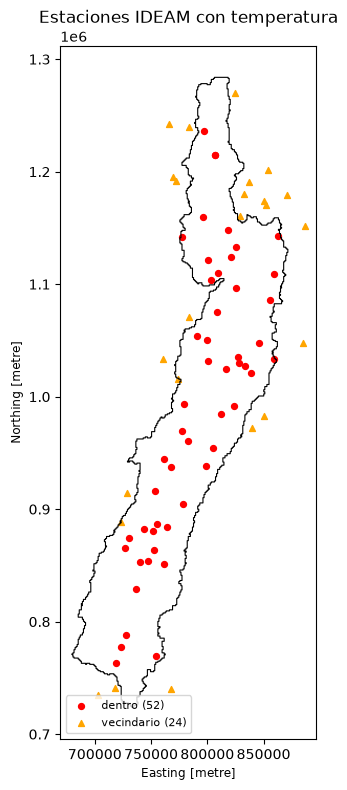

In [14]:
est = gpd.GeoDataFrame(t, geometry=gpd.points_from_xy(t.lon, t.lat), crs="EPSG:4326").to_crs(CRS)
cuenca = gpd.read_file(CUENCA).to_crs(CRS)
poli = cuenca.union_all() if hasattr(cuenca, "union_all") else cuenca.unary_union

dentro = est.within(poli)
dentro_buffer = est.within(poli.buffer(BUFFER_KM * 1000))
vecino = dentro_buffer & ~dentro
est["ubicacion"] = np.select([dentro, vecino], ["dentro", "vecindario"], "fuera")

sel = est[est.ubicacion.isin(USAR) & ~est.CODIGO.isin(QUITAR)].copy()
print(est.ubicacion.value_counts().drop("fuera", errors="ignore").to_string())
print(f"\nEstaciones usadas en la regresión: {len(sel)}  (ubicaciones {USAR}; descartadas a mano: {len(QUITAR)})")
print(f"Rango de elevación de las estaciones: {sel.ELEV.min():.0f} – {sel.ELEV.max():.0f} m")

fig, ax = plt.subplots(figsize=(6, 9))
cuenca.boundary.plot(ax=ax, color="k", lw=0.8)
for u, (mk, col) in {"dentro": ("o", "red"), "vecindario": ("^", "orange")}.items():
    s = est[est.ubicacion == u]
    ax.scatter(s.geometry.x, s.geometry.y, marker=mk, s=18, color=col, label=f"{u} ({len(s)})")
ax.set_title("Estaciones IDEAM con temperatura")
ax.set_aspect("equal"); ax.legend(loc="lower left", fontsize=8)
plt.show()

## 4. Regresión lineal temperatura–elevación
Para cada variable se ajusta $T = a + bZ$ por mínimos cuadrados. Luego $T_0 = a$ y $\alpha = -b$, con $Z$ en metros.

$$R^2 = 1 - \frac{\sum (T_i - \hat T_i)^2}{\sum (T_i - \bar T)^2}$$

Además se reporta el **intervalo de confianza del 95 %** de $\alpha$ y el **error típico** de la estimación (RMSE).

In [15]:
resultados, ajustes = [], {}
for v, nombre in VARIABLES.items():
    s = sel[["CODIGO", "NOMBRE", "ELEV", v]].dropna()
    Z, T = s["ELEV"].to_numpy(float), s[v].to_numpy(float)
    lr = stats.linregress(Z, T)
    T0, alpha = lr.intercept, -lr.slope
    T_hat = T0 - alpha * Z
    r2 = 1 - np.sum((T - T_hat) ** 2) / np.sum((T - T.mean()) ** 2)
    ic = stats.t.ppf(0.975, len(Z) - 2) * lr.stderr
    ajustes[v] = {"s": s, "Z": Z, "T": T, "T0": T0, "alpha": alpha, "r2": r2}
    resultados.append({
        "variable": nombre, "clave": v, "n_estaciones": len(Z),
        "T0_C": T0, "alpha_C_por_m": alpha, "alpha_C_por_km": alpha * 1000,
        "IC95_alpha_C_por_km": ic * 1000, "R2": r2,
        "RMSE_C": np.sqrt(np.mean((T - T_hat) ** 2)),
        "Z_min_m": Z.min(), "Z_max_m": Z.max(),
        "ecuacion": f"{v.capitalize()} = {T0:.2f} − {alpha:.5f}·Z",
    })

tabla = pd.DataFrame(resultados)
display(tabla.drop(columns="clave").round({"T0_C": 2, "alpha_C_por_m": 5, "alpha_C_por_km": 2,
                                           "IC95_alpha_C_por_km": 2, "R2": 3, "RMSE_C": 2}))

,variable,n_estaciones,T0_C,alpha_C_por_m,alpha_C_por_km,IC95_alpha_C_por_km,R2,RMSE_C,Z_min_m,Z_max_m,ecuacion
0,Temperatura máxima media,73,36.33,0.00711,7.11,0.47,0.929,1.22,500.0,4150.0,Tmax = 36.33 − 0.00711·Z
1,Temperatura mínima media,72,24.30,0.00574,5.74,0.31,0.950,0.81,530.0,4150.0,Tmin = 24.30 − 0.00574·Z
2,Temperatura media,73,29.99,0.00640,6.40,0.29,0.964,0.77,530.0,4150.0,Tmed = 29.99 − 0.00640·Z


## 5. Diagramas de dispersión

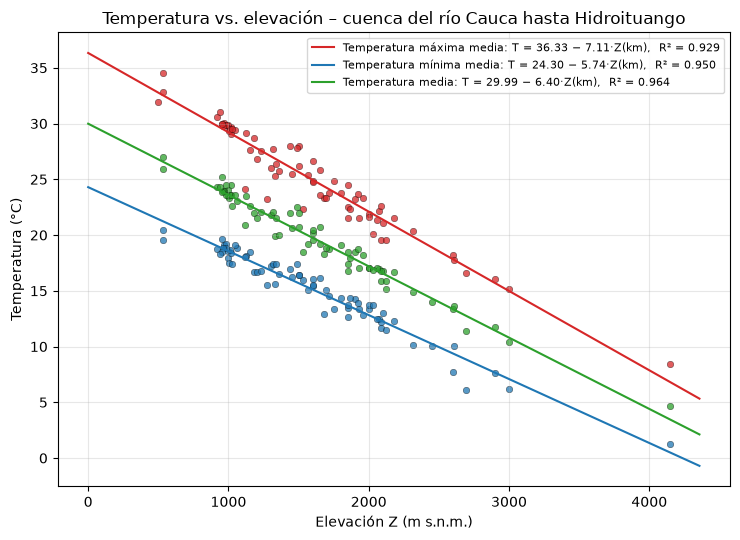

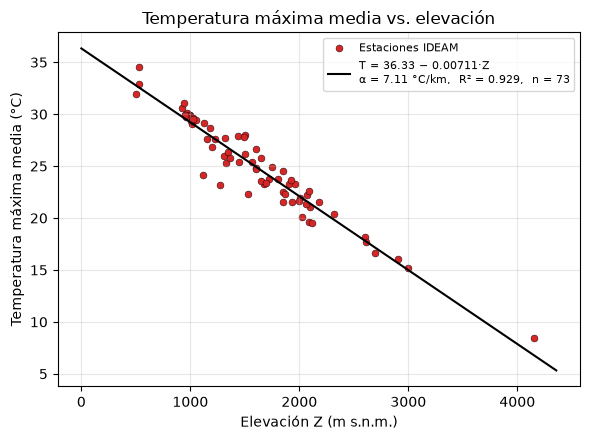

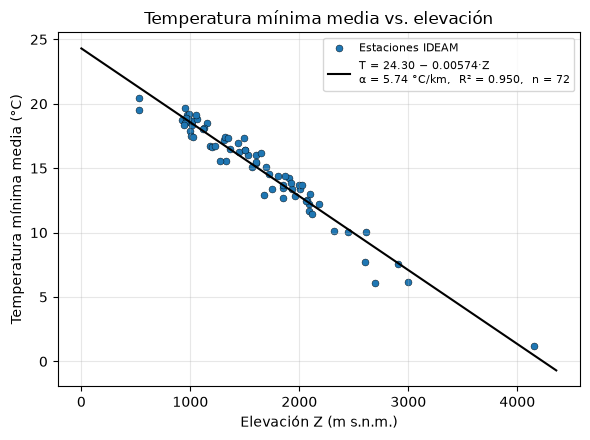

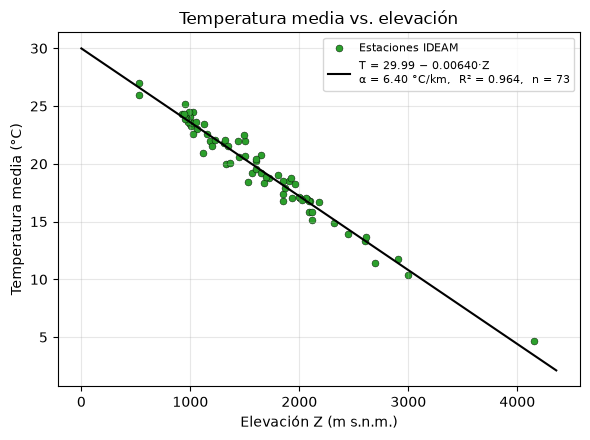

In [16]:
zz = np.linspace(0, max(a["Z"].max() for a in ajustes.values()) * 1.05, 100)

# Figura conjunta (las tres variables)
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for v, a in ajustes.items():
    ax.scatter(a["Z"], a["T"], s=22, color=COLORES[v], alpha=0.75, edgecolor="k", lw=0.3)
    ax.plot(zz, a["T0"] - a["alpha"] * zz, color=COLORES[v],
            label=f"{VARIABLES[v]}: T = {a['T0']:.2f} − {a['alpha']*1000:.2f}·Z(km),  R² = {a['r2']:.3f}")
ax.set_xlabel("Elevación Z (m s.n.m.)"); ax.set_ylabel("Temperatura (°C)")
ax.set_title("Temperatura vs. elevación – cuenca del río Cauca hasta Hidroituango")
ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig("fig_T_vs_Z_conjunta.png", dpi=200)
plt.show()

# Una figura por variable (para el informe)
for v, a in ajustes.items():
    fig, ax = plt.subplots(figsize=(6, 4.5))
    ax.scatter(a["Z"], a["T"], s=25, color=COLORES[v], edgecolor="k", lw=0.3, label="Estaciones IDEAM")
    ax.plot(zz, a["T0"] - a["alpha"] * zz, "k-",
            label=f"T = {a['T0']:.2f} − {a['alpha']:.5f}·Z\nα = {a['alpha']*1000:.2f} °C/km,  R² = {a['r2']:.3f},  n = {len(a['Z'])}")
    ax.set_xlabel("Elevación Z (m s.n.m.)"); ax.set_ylabel(f"{VARIABLES[v]} (°C)")
    ax.set_title(f"{VARIABLES[v]} vs. elevación")
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
    fig.tight_layout(); fig.savefig(f"fig_T_vs_Z_{v}.png", dpi=200)
    plt.show()

## 6. Residuos: estaciones que se apartan de la recta
Un residuo positivo indica una estación **más cálida** de lo que predice su elevación; uno negativo, **más fría**.
Los residuos grandes pueden tener causas físicas, como un valle seco y abrigado, una ladera expuesta, el efecto de
isla de calor de una ciudad o la inversión térmica nocturna en fondos de valle. También pueden ser errores de
coordenadas o de elevación. Se marcan las estaciones con |residuo| > 2,5 veces el RMSE. Si decide descartar alguna,
agregue su código a `QUITAR` (sección 1) y vuelva a correr todo.

,variable,CODIGO,NOMBRE,ELEV,T_obs,residuo_C
181,tmax,54025010,San Jose Palmar,1115,24.17,-4.23
365,tmax,54015010,Pueblo Rico,1530,22.32,-3.13
454,tmax,26095180,San Emigdio,1272,23.22,-4.06
120,tmin,26185040,San Felix,2696,6.09,-2.74
23,tmed,27015070,A.Olaya Herrera,1490,22.49,2.03
181,tmed,54025010,San Jose Palmar,1115,20.90,-1.96


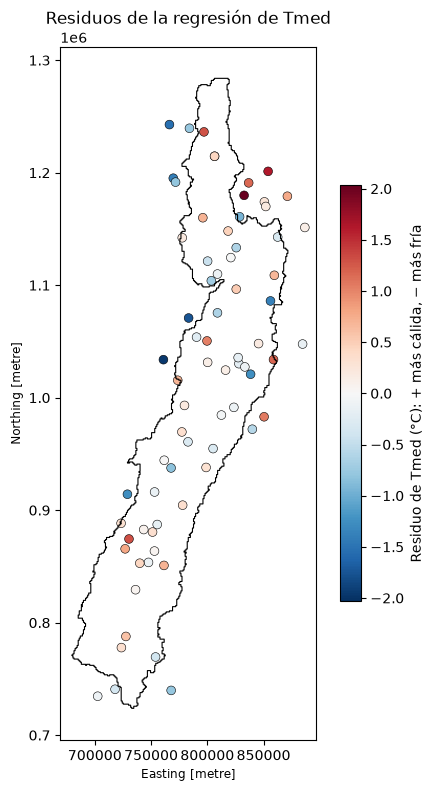

In [17]:
filas = []
for v, a in ajustes.items():
    s = a["s"].copy()
    s["residuo_C"] = a["T"] - (a["T0"] - a["alpha"] * a["Z"])
    s["variable"] = v
    rmse = np.sqrt(np.mean(s["residuo_C"] ** 2))
    filas.append(s[np.abs(s["residuo_C"]) > 2.5 * rmse].rename(columns={v: "T_obs"}))
atipicas = pd.concat(filas)
if atipicas.empty:
    print("Ninguna estación se aparta más de 2,5 RMSE de la recta.")
else:
    display(atipicas[["variable", "CODIGO", "NOMBRE", "ELEV", "T_obs", "residuo_C"]].round(2))

# Mapa de residuos de Tmed: ¿hay un patrón espacial (valle más cálido, vertientes más frías)?
a = ajustes["tmed"]
r = sel.loc[a["s"].index]
res = a["T"] - (a["T0"] - a["alpha"] * a["Z"])
fig, ax = plt.subplots(figsize=(6, 9))
cuenca.boundary.plot(ax=ax, color="k", lw=0.8)
lim = np.abs(res).max()
sc = ax.scatter(r.geometry.x, r.geometry.y, c=res, cmap="RdBu_r", vmin=-lim, vmax=lim, s=40, edgecolor="k", lw=0.4)
plt.colorbar(sc, ax=ax, shrink=0.6, label="Residuo de Tmed (°C): + más cálida, − más fría")
ax.set_title("Residuos de la regresión de Tmed"); ax.set_aspect("equal")
plt.show()

## 7. Comparación: solo cuenca, cuenca + vecindario y toda Colombia
Sirve para justificar qué estaciones usar y para discutir si el gradiente de la cuenca es "típico".

In [18]:
def ajuste_rapido(df_, v):
    s = df_[["ELEV", v]].dropna()
    lr = stats.linregress(s["ELEV"], s[v])
    return {"T0_C": lr.intercept, "alpha_C_por_km": -lr.slope * 1000, "R2": lr.rvalue ** 2, "n": len(s)}

grupos = {
    "Solo dentro de la cuenca": est[(est.ubicacion == "dentro") & ~est.CODIGO.isin(QUITAR)],
    "Dentro + vecindario": est[est.ubicacion.isin(["dentro", "vecindario"]) & ~est.CODIGO.isin(QUITAR)],
    "Toda Colombia": est,
}
comp = pd.DataFrame([{"grupo": g, "variable": v, **ajuste_rapido(df_, v)}
                     for g, df_ in grupos.items() for v in VARIABLES])
display(comp.pivot(index="grupo", columns="variable", values=["alpha_C_por_km", "T0_C", "R2", "n"]).round(2))

alpha_C_por_km               T0_C                  R2                  n              
variable                           tmax  tmed  tmin   tmax   tmed   tmin  tmax  tmed  tmin   tmax   tmed   tmin
grupo                                                                                                          
Dentro + vecindario                7.11  6.40  5.74  36.33  29.99  24.30  0.93  0.96  0.95   73.0   73.0   72.0
Solo dentro de la cuenca           7.21  6.41  5.73  36.65  30.10  24.24  0.97  0.98  0.96   51.0   50.0   50.0
Toda Colombia                      5.59  5.55  5.64  33.35  28.23  23.67  0.91  0.96  0.96  445.0  450.0  457.0

## 8. Elementos para la interpretación física

In [19]:
a_max, a_min, a_med = (ajustes[k] for k in ("tmax", "tmin", "tmed"))
print("Gradientes térmicos verticales (°C/km):")
for k, a in ajustes.items():
    print(f"  {VARIABLES[k]:27s} α = {a['alpha']*1000:5.2f}")
print("  Referencias: atmósfera estándar 6,5 | adiabático seco 9,8 | adiabático saturado ≈ 4–6 en el trópico")

z0 = a_med["T0"] / a_med["alpha"]
print(f"\nElevación donde Tmed = 0 °C según la recta: {z0:,.0f} m "
      "(compárela con el límite inferior de los glaciares de la cordillera Central)")

amp0 = a_max["T0"] - a_min["T0"]
damp = (a_max["alpha"] - a_min["alpha"]) * 1000
print(f"\nAmplitud térmica diaria media (Tmax − Tmin): {amp0:.1f} °C a nivel del mar extrapolado; "
      f"cambia {-damp:+.2f} °C por km de elevación")
for z in (1000, 2000, 3000):
    print(f"  a {z} m: Tmax − Tmin ≈ {(a_max['T0'] - a_max['alpha']*z) - (a_min['T0'] - a_min['alpha']*z):.1f} °C")

dif = (sel["tmed"] - (sel["tmax"] + sel["tmin"]) / 2).dropna()
print(f"\nEn la cuenca, Tmed observada − (Tmax+Tmin)/2 = {dif.mean():+.2f} ± {dif.std():.2f} °C "
      f"(n = {len(dif)}). Úselo para justificar Tmed = (Tmax+Tmin)/2 en el punto 6.")

try:
    import rasterio
    with rasterio.open(DEM) as src:
        dem = src.read(1, masked=True)
    print(f"\nElevación de la cuenca (DEM): {dem.min():.0f} – {dem.max():.0f} m | "
          f"estaciones: {sel.ELEV.min():.0f} – {sel.ELEV.max():.0f} m")
    print(f"Porcentaje del área por encima de la estación más alta: {(dem > sel.ELEV.max()).sum() / dem.count() * 100:.1f} %")
except Exception as e:
    print("\n(No se pudo leer el DEM para comparar rangos de elevación:", e, ")")

Gradientes térmicos verticales (°C/km):
  Temperatura máxima media    α =  7.11
  Temperatura mínima media    α =  5.74
  Temperatura media           α =  6.40
  Referencias: atmósfera estándar 6,5 | adiabático seco 9,8 | adiabático saturado ≈ 4–6 en el trópico

Elevación donde Tmed = 0 °C según la recta: 4,689 m (compárela con el límite inferior de los glaciares de la cordillera Central)

Amplitud térmica diaria media (Tmax − Tmin): 12.0 °C a nivel del mar extrapolado; cambia -1.38 °C por km de elevación
  a 1000 m: Tmax − Tmin ≈ 10.7 °C
  a 2000 m: Tmax − Tmin ≈ 9.3 °C
  a 3000 m: Tmax − Tmin ≈ 7.9 °C

En la cuenca, Tmed observada − (Tmax+Tmin)/2 = -0.32 ± 0.31 °C (n = 68). Úselo para justificar Tmed = (Tmax+Tmin)/2 en el punto 6.

Elevación de la cuenca (DEM): 322 – 5141 m | estaciones: 500 – 4150 m
Porcentaje del área por encima de la estación más alta: 0.4 %


### Guía para escribir la interpretación (ajústela a sus números)
- **Por qué disminuye la temperatura con la altura:** al ascender, el aire se expande porque la presión es menor y se
  enfría adiabáticamente. Además, la superficie que calienta el aire está más lejos del aire de las capas bajas y la
  atmósfera es más delgada y seca, por lo que retiene menos radiación de onda larga.
- **Valor de α:** un valor entre el gradiente adiabático saturado (≈ 4–6 °C/km) y el seco (9,8 °C/km), cercano a
  6,5 °C/km, indica una atmósfera húmeda, típica de los Andes tropicales.
- **α de Tmax frente a α de Tmin:** si α(Tmax) > α(Tmin), la amplitud térmica diaria disminuye con la altura. En
  las partes bajas, el valle cálido y relativamente seco se calienta mucho de día. En las partes altas, la nubosidad
  frecuente limita el calentamiento diurno.
- **T₀ no es una temperatura real:** es la extrapolación de la recta a Z = 0. Si la cuenca no tiene estaciones por
  debajo de unos 500 m, T₀ puede salir mayor que la temperatura de las llanuras costeras.
- **R² y dispersión:** un R² alto indica que la elevación explica casi toda la variación espacial de la temperatura
  media. La dispersión que queda (sección 6) refleja efectos locales: valle seco y abrigado, exposición de ladera,
  ciudades, inversiones nocturnas.
- **Comparación (sección 7):** si el gradiente de la cuenca difiere del de toda Colombia, la relación regional es
  más apropiada que una nacional para construir los mapas del punto 5.

## 9. Guardar resultados
- `resultados_regresion_T.csv`: la tabla de la sección 4, para el informe.
- `parametros_T.json`: $T_0$ y $\alpha$ de cada variable, para el notebook del punto 5.
- `estaciones_T_seleccionadas.csv` / `.gpkg`: estaciones usadas, para cargarlas en QGIS si quiere mostrarlas en un mapa.

In [20]:
tabla.round(6).to_csv("resultados_regresion_T.csv", index=False, encoding="utf-8-sig")
parametros = {v: {"T0": float(a["T0"]), "alpha_C_por_m": float(a["alpha"]), "R2": float(a["r2"]), "n": int(len(a["Z"]))}
              for v, a in ajustes.items()}
with open("parametros_T.json", "w", encoding="utf-8") as f:
    json.dump(parametros, f, indent=2, ensure_ascii=False)
cols = ["CODIGO", "ZONA_HIDRO", "CAT", "NOMBRE", "MUNICIPIO", "DEPARTAMENTO", "ELEV", "lon", "lat", "ubicacion",
        "tmax", "tmin", "tmed"]
sel[cols].round(3).to_csv("estaciones_T_seleccionadas.csv", index=False, encoding="utf-8-sig")
sel[cols + ["geometry"]].to_file("estaciones_T_seleccionadas.gpkg", driver="GPKG")
print(json.dumps(parametros, indent=2, ensure_ascii=False))

{
  "tmax": {
    "T0": 36.331602555469416,
    "alpha_C_por_m": 0.007114622335821216,
    "R2": 0.928771502372695,
    "n": 73
  },
  "tmin": {
    "T0": 24.29559868163365,
    "alpha_C_por_m": 0.005736107115755401,
    "R2": 0.950294128592787,
    "n": 72
  },
  "tmed": {
    "T0": 29.988094562040587,
    "alpha_C_por_m": 0.006395361401716312,
    "R2": 0.9641172840650017,
    "n": 73
  }
}
